# [2-b] MLP 개선: Dropout · 학습률 낮추기 · Early Stopping

[2]의 MLP는 train acc는 0.96까지 오르는데 val acc가 0.49 ~ 0.78로 들쭉날쭉했어요 (과적합).
세 가지 버전을 **같은 조건**에서 비교합니다. 모두 Early Stopping을 씁니다.

| 버전 | Dropout | 학습률(lr) |
|---|---|---|
| A 기본 | 없음 | 0.001 |
| B Dropout | 0.5 | 0.001 |
| C Dropout + lr↓ | 0.5 | 0.0001 |

- **Dropout**: 학습할 때 뉴런을 무작위로 꺼서, 특정 뉴런에만 기대서 외우는 걸 막음 (AI개론 12차시)
- **lr 낮추기**: 한 번에 가중치를 조금씩만 바꿔서 val이 덜 출렁이게
- **Early Stopping**: val loss가 5번 연속 안 좋아지면 멈추고, 제일 좋았던 때 모델로 되돌림

In [1]:
import os
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, Subset
from torchvision import datasets, transforms

plt.rcParams["font.family"] = "Malgun Gothic"
plt.rcParams["axes.unicode_minus"] = False

torch.manual_seed(42)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(device)

cuda


In [2]:
# 검증은 A040 선수 (tk_2, tk_3와 똑같이 나눔 → 결과 비교 가능)
VAL_PERSON = "A040"

def make_loaders(img_size):
    transform = transforms.Compose([
        transforms.Resize((img_size, img_size)),
        transforms.ToTensor(),
        transforms.Normalize((0.5, 0.5, 0.5), (0.5, 0.5, 0.5)),
    ])
    dataset = datasets.ImageFolder("tk_crops", transform=transform)
    train_idx = [i for i, (p, _) in enumerate(dataset.samples) if VAL_PERSON not in os.path.basename(p)]
    val_idx = [i for i, (p, _) in enumerate(dataset.samples) if VAL_PERSON in os.path.basename(p)]
    train_loader = DataLoader(Subset(dataset, train_idx), batch_size=32, shuffle=True)
    val_loader = DataLoader(Subset(dataset, val_idx), batch_size=32, shuffle=False)
    return dataset.classes, train_loader, val_loader

In [3]:
classes, train_loader, val_loader = make_loaders(64)
print("클래스:", classes)
print("train:", len(train_loader.dataset), " val:", len(val_loader.dataset))

클래스: ['1_start', '2_middle', '3_end']
train: 933  val: 264


In [4]:
criterion = nn.CrossEntropyLoss()

def train_model(model, optimizer, train_loader, val_loader, save_path, max_epochs=50, patience=5):
    """학습 + Early Stopping
    - val loss가 좋아질 때마다 모델을 파일(save_path)로 저장
    - patience번 연속으로 안 좋아지면 학습을 멈춤
    - 끝나면 제일 좋았던 모델을 다시 불러옴
    """
    history = {"train_loss": [], "train_acc": [], "val_loss": [], "val_acc": []}
    best_loss = float("inf")    # 지금까지 제일 낮은 val loss (처음엔 무한대)
    wait = 0                    # 몇 번 연속으로 안 좋아졌는지

    for epoch in range(max_epochs):
        # ----- 학습 -----
        model.train()
        total_loss, correct, total = 0, 0, 0
        for images, labels in train_loader:
            images, labels = images.to(device), labels.to(device)
            optimizer.zero_grad()
            outputs = model(images)
            loss = criterion(outputs, labels)
            loss.backward()
            optimizer.step()
            total_loss += loss.item() * labels.size(0)
            correct += (outputs.argmax(1) == labels).sum().item()
            total += labels.size(0)
        train_loss, train_acc = total_loss / total, correct / total

        # ----- 검증 -----
        model.eval()
        total_loss, correct, total = 0, 0, 0
        with torch.no_grad():
            for images, labels in val_loader:
                images, labels = images.to(device), labels.to(device)
                outputs = model(images)
                total_loss += criterion(outputs, labels).item() * labels.size(0)
                correct += (outputs.argmax(1) == labels).sum().item()
                total += labels.size(0)
        val_loss, val_acc = total_loss / total, correct / total

        history["train_loss"].append(train_loss); history["train_acc"].append(train_acc)
        history["val_loss"].append(val_loss); history["val_acc"].append(val_acc)
        msg = f"Epoch {epoch + 1:2d} | train loss {train_loss:.4f} acc {train_acc:.4f} | val loss {val_loss:.4f} acc {val_acc:.4f}"

        # ----- Early Stopping -----
        if val_loss < best_loss:
            best_loss = val_loss
            wait = 0
            torch.save(model.state_dict(), save_path)     # 제일 좋은 모델 저장
            msg += "  ← best 저장"
        else:
            wait += 1
            msg += f"  (좋아지지 않음 {wait}/{patience})"
        print(msg)
        if wait >= patience:
            print(f"→ {patience}번 연속 val loss가 좋아지지 않아서 {epoch + 1} epoch에서 멈춤")
            break

    model.load_state_dict(torch.load(save_path))          # 제일 좋았던 모델로 되돌리기
    return history

In [5]:
def evaluate(model, val_loader, n_classes=3):
    """정확도와 혼동행렬 (행 = 정답, 열 = 예측)"""
    model.eval()
    cm = np.zeros((n_classes, n_classes), dtype=int)
    with torch.no_grad():
        for images, labels in val_loader:
            preds = model(images.to(device)).argmax(1).cpu()
            for t, p in zip(labels, preds):
                cm[t, p] += 1
    acc = np.trace(cm) / cm.sum()       # 대각선 합 / 전체
    return acc, cm

def plot_cm(cm, classes, title):
    plt.imshow(cm, cmap="Blues")
    plt.xticks(range(len(classes)), classes); plt.yticks(range(len(classes)), classes)
    plt.xlabel("예측"); plt.ylabel("정답"); plt.title(title)
    for i in range(len(classes)):
        for j in range(len(classes)):
            plt.text(j, i, cm[i, j], ha="center", va="center")

## MLP 만드는 함수 (dropout 값만 바꿔서 쓰기)

In [6]:
def make_mlp(dropout):
    return nn.Sequential(
        nn.Flatten(),                 # (N, 3, 64, 64) → (N, 12288)
        nn.Linear(3 * 64 * 64, 512),
        nn.ReLU(),
        nn.Dropout(dropout),          # dropout=0이면 아무것도 안 함
        nn.Linear(512, 128),
        nn.ReLU(),
        nn.Dropout(dropout),
        nn.Linear(128, 3),
    ).to(device)

print(make_mlp(0.5))

Sequential(
  (0): Flatten(start_dim=1, end_dim=-1)
  (1): Linear(in_features=12288, out_features=512, bias=True)
  (2): ReLU()
  (3): Dropout(p=0.5, inplace=False)
  (4): Linear(in_features=512, out_features=128, bias=True)
  (5): ReLU()
  (6): Dropout(p=0.5, inplace=False)
  (7): Linear(in_features=128, out_features=3, bias=True)
)


## A. 기본 (Dropout 없음, lr 0.001)

In [7]:
results = {}
torch.manual_seed(42)                       # 버전마다 같은 시작점에서 출발 (공평한 비교)
model_a = make_mlp(dropout=0.0)
opt_a = optim.Adam(model_a.parameters(), lr=0.001)
results["A 기본"] = train_model(model_a, opt_a, train_loader, val_loader, "best_mlp_A.pth")

Epoch  1 | train loss 1.2994 acc 0.4116 | val loss 0.9440 acc 0.5682  ← best 저장
Epoch  2 | train loss 0.8279 acc 0.6088 | val loss 0.9170 acc 0.5189  ← best 저장
Epoch  3 | train loss 0.6256 acc 0.7353 | val loss 0.6856 acc 0.6970  ← best 저장
Epoch  4 | train loss 0.5221 acc 0.7696 | val loss 0.6712 acc 0.7273  ← best 저장
Epoch  5 | train loss 0.4173 acc 0.8199 | val loss 0.6821 acc 0.6818  (좋아지지 않음 1/5)
Epoch  6 | train loss 0.3957 acc 0.8317 | val loss 0.7137 acc 0.6553  (좋아지지 않음 2/5)
Epoch  7 | train loss 0.4010 acc 0.8328 | val loss 0.6712 acc 0.7121  ← best 저장
Epoch  8 | train loss 0.3087 acc 0.8596 | val loss 0.9661 acc 0.6439  (좋아지지 않음 1/5)
Epoch  9 | train loss 0.3148 acc 0.8746 | val loss 0.7064 acc 0.7273  (좋아지지 않음 2/5)
Epoch 10 | train loss 0.2981 acc 0.8714 | val loss 0.7835 acc 0.6629  (좋아지지 않음 3/5)
Epoch 11 | train loss 0.2025 acc 0.9207 | val loss 0.8078 acc 0.6932  (좋아지지 않음 4/5)
Epoch 12 | train loss 0.2248 acc 0.9132 | val loss 0.8830 acc 0.6667  (좋아지지 않음 5/5)
→ 5번 연속 val 

## B. Dropout 0.5 (lr 0.001)

In [8]:
torch.manual_seed(42)
model_b = make_mlp(dropout=0.5)
opt_b = optim.Adam(model_b.parameters(), lr=0.001)
results["B Dropout"] = train_model(model_b, opt_b, train_loader, val_loader, "best_mlp_B.pth")

Epoch  1 | train loss 1.4555 acc 0.3762 | val loss 1.0960 acc 0.3864  ← best 저장
Epoch  2 | train loss 1.1699 acc 0.3805 | val loss 1.0632 acc 0.5455  ← best 저장
Epoch  3 | train loss 1.0472 acc 0.4577 | val loss 0.9750 acc 0.5379  ← best 저장
Epoch  4 | train loss 0.9480 acc 0.5230 | val loss 0.8937 acc 0.6364  ← best 저장
Epoch  5 | train loss 0.8557 acc 0.5863 | val loss 0.8865 acc 0.5682  ← best 저장
Epoch  6 | train loss 0.7991 acc 0.6195 | val loss 0.8184 acc 0.5871  ← best 저장
Epoch  7 | train loss 0.8330 acc 0.6034 | val loss 0.7815 acc 0.6667  ← best 저장
Epoch  8 | train loss 0.7461 acc 0.6549 | val loss 0.7590 acc 0.6326  ← best 저장
Epoch  9 | train loss 0.6882 acc 0.6902 | val loss 0.7991 acc 0.6326  (좋아지지 않음 1/5)
Epoch 10 | train loss 0.6540 acc 0.6967 | val loss 0.7841 acc 0.6098  (좋아지지 않음 2/5)
Epoch 11 | train loss 0.6166 acc 0.7245 | val loss 0.6721 acc 0.6818  ← best 저장
Epoch 12 | train loss 0.5571 acc 0.7588 | val loss 0.8032 acc 0.6402  (좋아지지 않음 1/5)
Epoch 13 | train loss 0.6103

## C. Dropout 0.5 + lr 0.0001

In [9]:
torch.manual_seed(42)
model_c = make_mlp(dropout=0.5)
opt_c = optim.Adam(model_c.parameters(), lr=0.0001)
results["C Dropout+lr↓"] = train_model(model_c, opt_c, train_loader, val_loader, "best_mlp_C.pth")

Epoch  1 | train loss 1.1010 acc 0.3751 | val loss 1.0653 acc 0.3523  ← best 저장
Epoch  2 | train loss 1.0589 acc 0.4341 | val loss 1.0097 acc 0.5492  ← best 저장
Epoch  3 | train loss 1.0108 acc 0.4812 | val loss 0.9628 acc 0.5530  ← best 저장
Epoch  4 | train loss 0.9392 acc 0.5520 | val loss 0.8919 acc 0.6742  ← best 저장
Epoch  5 | train loss 0.8716 acc 0.5938 | val loss 0.8941 acc 0.5947  (좋아지지 않음 1/5)
Epoch  6 | train loss 0.8088 acc 0.6463 | val loss 0.7984 acc 0.6742  ← best 저장
Epoch  7 | train loss 0.7556 acc 0.6870 | val loss 0.7700 acc 0.7008  ← best 저장
Epoch  8 | train loss 0.7104 acc 0.6999 | val loss 0.7478 acc 0.6402  ← best 저장
Epoch  9 | train loss 0.6792 acc 0.7160 | val loss 0.8108 acc 0.6477  (좋아지지 않음 1/5)
Epoch 10 | train loss 0.6398 acc 0.7256 | val loss 0.7119 acc 0.6856  ← best 저장
Epoch 11 | train loss 0.6105 acc 0.7513 | val loss 0.6834 acc 0.7121  ← best 저장
Epoch 12 | train loss 0.5883 acc 0.7663 | val loss 0.7270 acc 0.6591  (좋아지지 않음 1/5)
Epoch 13 | train loss 0.5745

## 비교

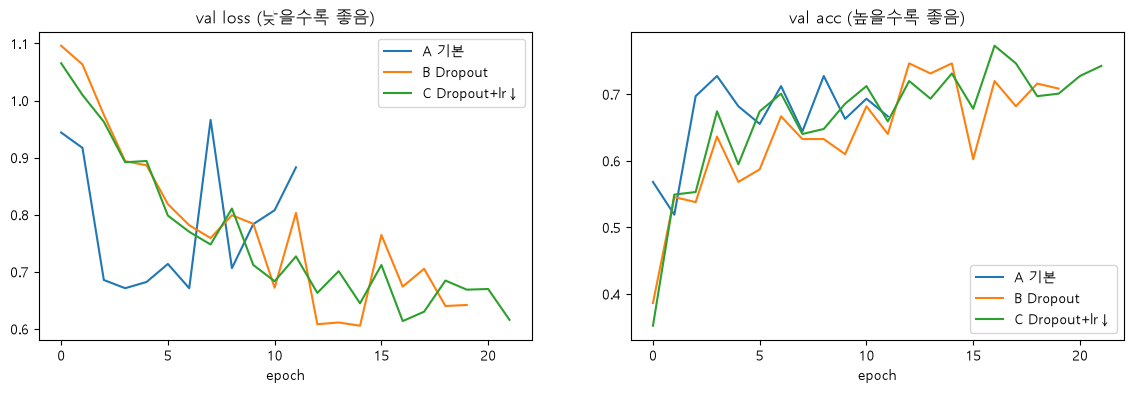

In [10]:
plt.figure(figsize=(14, 4))
plt.subplot(1, 2, 1)
for name, h in results.items():
    plt.plot(h["val_loss"], label=name)
plt.title("val loss (낮을수록 좋음)"); plt.xlabel("epoch"); plt.legend()
plt.subplot(1, 2, 2)
for name, h in results.items():
    plt.plot(h["val_acc"], label=name)
plt.title("val acc (높을수록 좋음)"); plt.xlabel("epoch"); plt.legend()
plt.show()

버전              | 학습한 epoch | 최종 val acc
A 기본            |          12 | 0.7121
B Dropout       |          20 | 0.7462
C Dropout+lr↓   |          22 | 0.7727


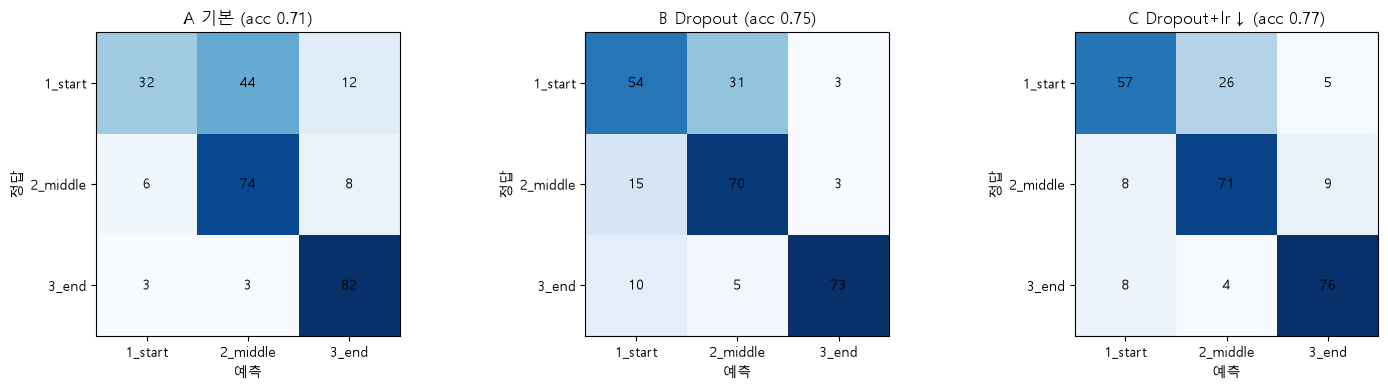

In [11]:
# 각 버전의 "제일 좋았던 모델"로 최종 평가
models = {"A 기본": model_a, "B Dropout": model_b, "C Dropout+lr↓": model_c}

print(f"{'버전':15s} | 학습한 epoch | 최종 val acc")
plt.figure(figsize=(15, 4))
for k, (name, m) in enumerate(models.items()):
    acc, cm = evaluate(m, val_loader)
    print(f"{name:15s} | {len(results[name]['val_acc']):11d} | {acc:.4f}")
    plt.subplot(1, 3, k + 1)
    plot_cm(cm, classes, f"{name} (acc {acc:.2f})")
plt.tight_layout(); plt.show()

## 생각해볼 것
1. 그래프에서 val 곡선이 제일 덜 출렁이는 버전은?
2. lr을 낮추면 학습한 epoch 수가 어떻게 달라졌어? (Early Stopping이 언제 멈췄는지)
3. Dropout은 학습할 때만 켜지고 평가할 때는 꺼져요. 코드에서 어느 줄이 그걸 정해줄까? (`model.train()` / `model.eval()`)
4. 그래도 [3] CNN(val acc 0.85)보다 낮다면, MLP 자체의 한계는 뭘까?